# 12-5. A3 Ridge Logistic 오차행렬

GTX-A 126개 격자를 대상으로 **12-4와 동일한 중첩 Leave-One-Station-Out 검증**을 재현한다.

- 종속변수: 역 권역 내 개통 후 수요 비중 증가(1) / 비증가(0)
- 후보모형: A1~A4
- 내부 학습 권역에서 후보모형과 Ridge 규제강도 `C` 선택
- 외부 검증역은 모형·하이퍼파라미터 선택에서 완전히 제외
- 분류 기준: OOF 예측확률 `0.5`
- 결과: 전체 및 대곡·운정중앙·킨텍스별 오차행렬

오차행렬의 행은 실제값, 열은 예측값이다. 각 칸에는 **격자 수와 실제 집단 내 비율**을 함께 표시한다.

In [1]:
from pathlib import Path
import importlib.util
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import (
    confusion_matrix, accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    brier_score_loss
)
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut

warnings.filterwarnings('ignore')
sns.set_theme(style='white', font='AppleGothic')
plt.rcParams['axes.unicode_minus'] = False

HERE = Path.cwd()
if not (HERE / '12-2_Ridge_Logistic_예측성능_개선실험.py').exists():
    HERE = Path('gtx_a_bus_analysis/analysis').resolve()
BASE_SCRIPT = HERE / '12-2_Ridge_Logistic_예측성능_개선실험.py'
spec = importlib.util.spec_from_file_location('ridge_experiment_12_2', BASE_SCRIPT)
base = importlib.util.module_from_spec(spec)
spec.loader.exec_module(base)

CANDIDATES = [
    {'name': 'A1', 'description': '수요비중+보행시간+경쟁목적지',
     'features': ['pre_share_pct', 'walk_min', 'competing_share']},
    {'name': 'A2', 'description': '로그승차+보행시간+경쟁목적지',
     'features': ['log1p_board_2024', 'walk_min', 'competing_share']},
    {'name': 'A3', 'description': '수요비중+로그승차+보행시간+경쟁목적지',
     'features': ['pre_share_pct', 'log1p_board_2024', 'walk_min', 'competing_share']},
    {'name': 'A4', 'description': '보행시간+경쟁목적지',
     'features': ['walk_min', 'competing_share']},
]

print('분석 모형: A1~A4 및 C를 학습 권역 내부에서 선택하는 중첩검증')
print('분류 기준: OOF 예측확률 ≥ 0.5이면 증가(1)')

분석 모형: A1~A4 및 C를 학습 권역 내부에서 선택하는 중첩검증
분류 기준: OOF 예측확률 ≥ 0.5이면 증가(1)


In [2]:
def nested_oof_predictions(df):
    sample = df.dropna(subset=['nearest_station', 'share_increase']).copy()
    y = sample['share_increase'].astype(int)
    groups = sample['nearest_station']
    outer = LeaveOneGroupOut()

    oof_probability = pd.Series(index=sample.index, dtype=float)
    oof_prediction = pd.Series(index=sample.index, dtype='Int64')
    selection_rows = []

    for train_idx, test_idx in outer.split(sample, y, groups):
        train = sample.iloc[train_idx]
        test = sample.iloc[test_idx]
        y_train = y.iloc[train_idx]
        train_groups = groups.iloc[train_idx]
        test_station = groups.iloc[test_idx].iloc[0]
        candidate_results = []

        for candidate in CANDIDATES:
            features = candidate['features']
            search = GridSearchCV(
                base.make_pipeline(features, 'linear'),
                {'model__C': base.C_VALUES},
                scoring='roc_auc',
                cv=LeaveOneGroupOut().split(train[features], y_train, train_groups),
                refit=True,
                n_jobs=1,
            )
            search.fit(train[features], y_train)
            candidate_results.append({
                'candidate': candidate,
                'search': search,
                'inner_auc': search.best_score_,
                'C': search.best_params_['model__C'],
            })

        selected = max(candidate_results, key=lambda item: item['inner_auc'])
        features = selected['candidate']['features']
        probability = selected['search'].best_estimator_.predict_proba(test[features])[:, 1]
        prediction = (probability >= 0.5).astype(int)
        oof_probability.iloc[test_idx] = probability
        oof_prediction.iloc[test_idx] = prediction

        selection_rows.append({
            '외부 검증역': test_station,
            '선택 모형': selected['candidate']['name'],
            '내부 CV ROC-AUC': selected['inner_auc'],
            '선택 C': selected['C'],
            '검증 표본 수': len(test_idx),
        })

    result = sample[[base.ID, 'nearest_station', 'share_increase']].copy()
    result['OOF 증가확률'] = oof_probability
    result['OOF 예측'] = oof_prediction.astype(int)
    return result, pd.DataFrame(selection_rows)


df = base.load_data()
oof, selections = nested_oof_predictions(df)

print(f'전체 표본 수: {len(oof)}개')
print('실제 집단 분포:')
display(pd.crosstab(oof['nearest_station'], oof['share_increase'], margins=True))
print('외부 Fold별 내부 선택 결과:')
display(selections.round(4))

전체 표본 수: 126개
실제 집단 분포:
외부 Fold별 내부 선택 결과:


share_increase,0,1,All
nearest_station,,,
대곡,19,18,37
운정중앙,29,34,63
킨텍스,12,14,26
All,60,66,126


,외부 검증역,선택 모형,내부 CV ROC-AUC,선택 C,검증 표본 수
0,대곡,A3,0.7516,316.2278,37
1,운정중앙,A3,0.6821,1.0000,63
2,킨텍스,A3,0.7267,10.0000,26


In [3]:
def classification_summary(data, label):
    y_true = data['share_increase'].astype(int)
    y_pred = data['OOF 예측'].astype(int)
    y_prob = data['OOF 증가확률']
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    return {
        '구분': label,
        '표본 수': len(data),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_true, y_pred),
        'Sensitivity(증가 재현율)': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'Specificity(비증가 재현율)': specificity,
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'F1': f1_score(y_true, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'Brier Score': brier_score_loss(y_true, y_prob),
    }

summary_rows = [classification_summary(oof, '전체 OOF')]
for station in ['대곡', '운정중앙', '킨텍스']:
    summary_rows.append(classification_summary(oof[oof['nearest_station'] == station], station))
summary = pd.DataFrame(summary_rows)

display(summary.round(4).style.format({
    'Accuracy': '{:.3f}', 'Balanced Accuracy': '{:.3f}',
    'Sensitivity(증가 재현율)': '{:.3f}', 'Specificity(비증가 재현율)': '{:.3f}',
    'Precision': '{:.3f}', 'F1': '{:.3f}', 'ROC-AUC': '{:.3f}', 'Brier Score': '{:.3f}'
}))

,구분,표본 수,TN,FP,FN,TP,Accuracy,Balanced Accuracy,Sensitivity(증가 재현율),Specificity(비증가 재현율),Precision,F1,ROC-AUC,Brier Score
0,전체 OOF,126,26,34,17,49,0.595,0.588,0.742,0.433,0.590,0.658,0.655,0.243
1,대곡,37,4,15,2,16,0.540,0.550,0.889,0.210,0.516,0.653,0.687,0.253
2,운정중앙,63,11,18,4,30,0.651,0.631,0.882,0.379,0.625,0.732,0.760,0.224
3,킨텍스,26,11,1,11,3,0.538,0.566,0.214,0.917,0.750,0.333,0.732,0.274


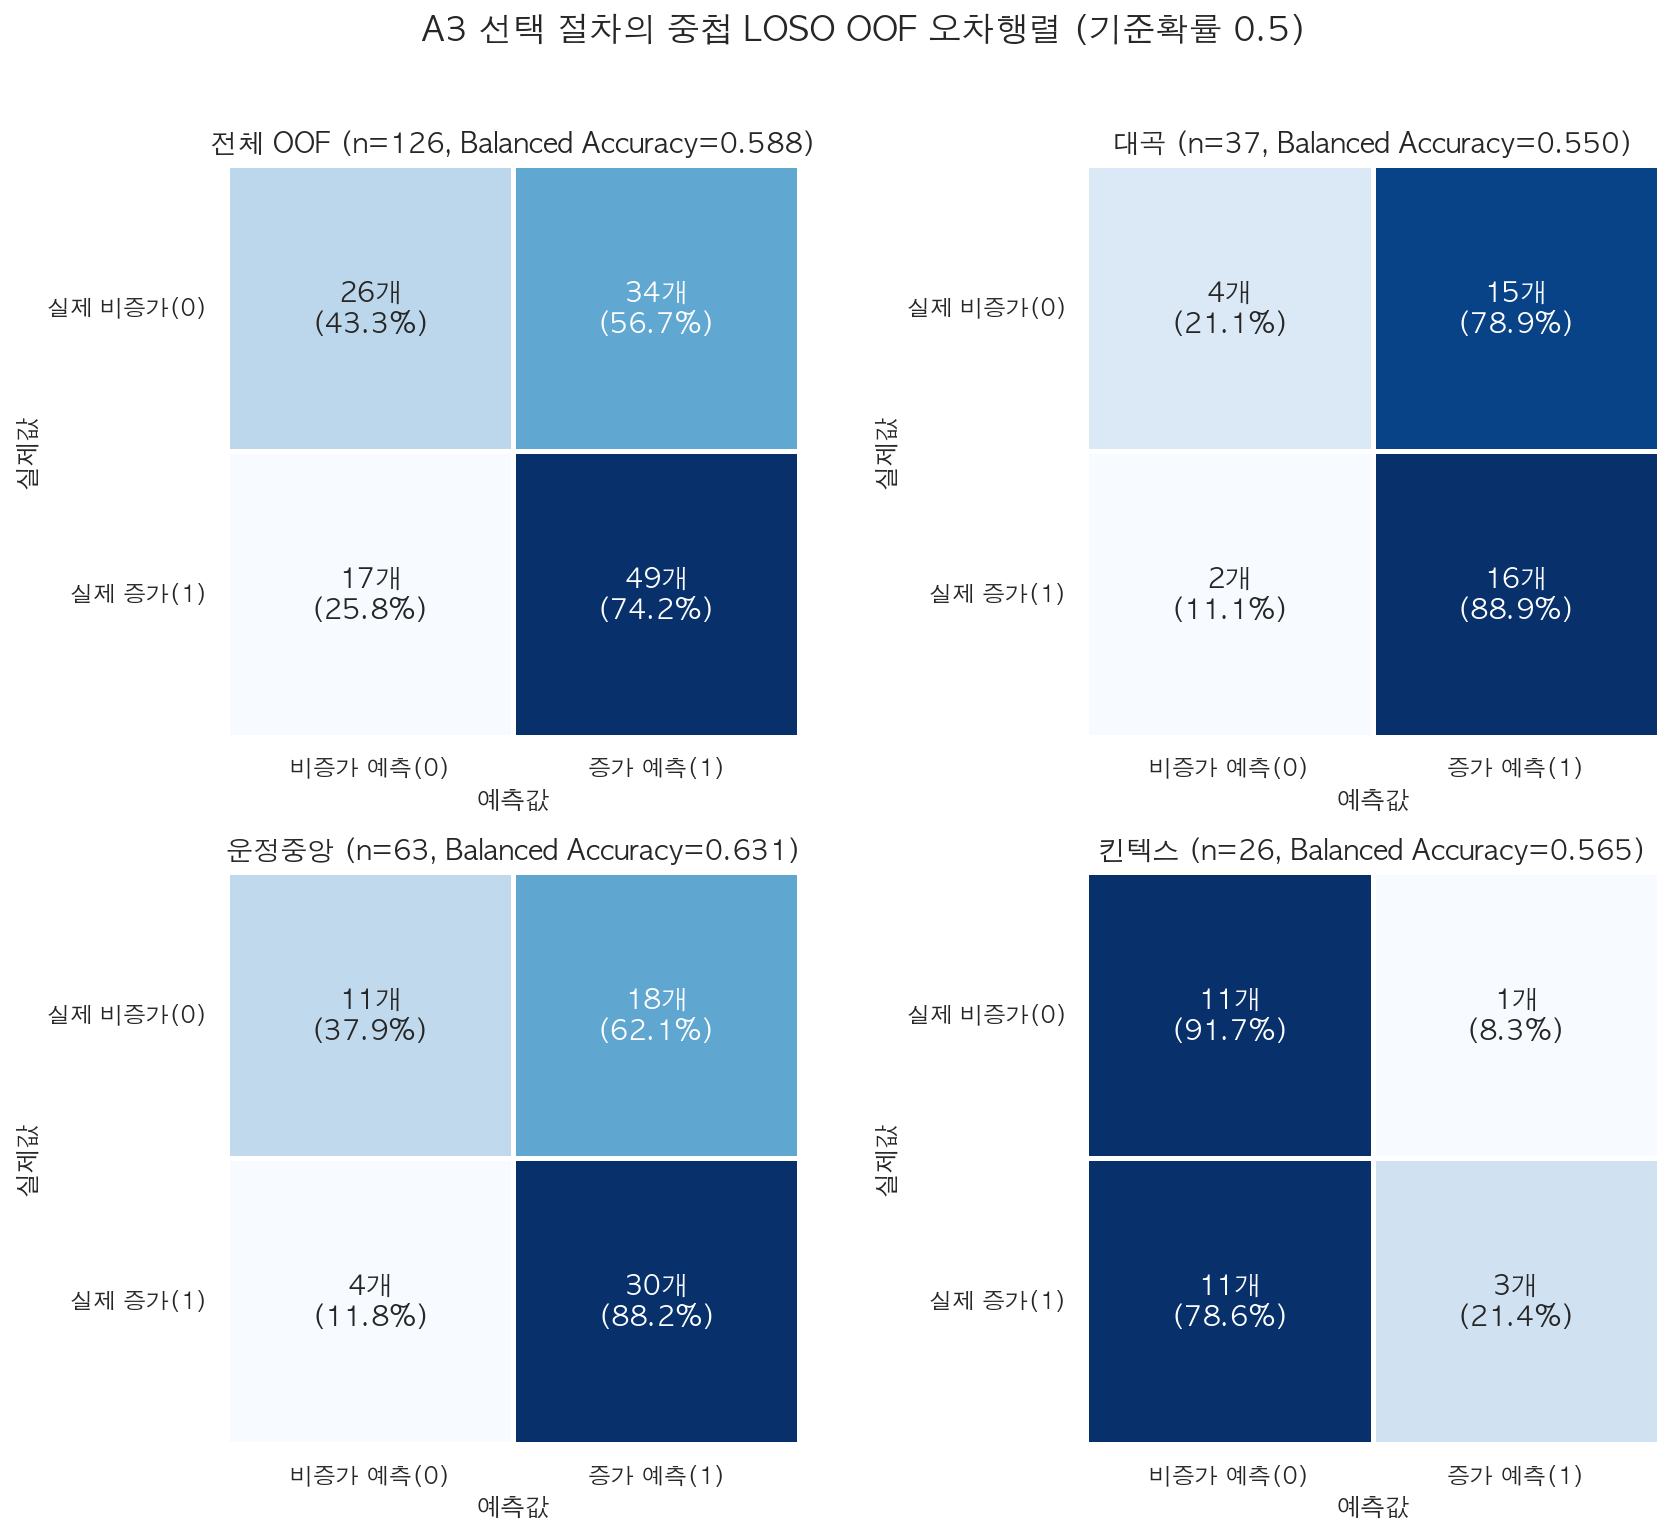

In [4]:
def matrix_annotations(cm):
    row_sum = cm.sum(axis=1, keepdims=True)
    row_pct = np.divide(cm, row_sum, out=np.zeros_like(cm, dtype=float), where=row_sum != 0) * 100
    return np.array([[f'{cm[i, j]}개\n({row_pct[i, j]:.1f}%)' for j in range(2)] for i in range(2)])

panels = [('전체 OOF', oof)] + [
    (station, oof[oof['nearest_station'] == station])
    for station in ['대곡', '운정중앙', '킨텍스']
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (title, data) in zip(axes.flat, panels):
    cm = confusion_matrix(data['share_increase'], data['OOF 예측'], labels=[0, 1])
    sns.heatmap(
        cm, annot=matrix_annotations(cm), fmt='', cmap='Blues', cbar=False,
        linewidths=1.5, linecolor='white', square=True, ax=ax,
        xticklabels=['비증가 예측(0)', '증가 예측(1)'],
        yticklabels=['실제 비증가(0)', '실제 증가(1)'],
        annot_kws={'size': 13, 'weight': 'bold'},
    )
    bal = balanced_accuracy_score(data['share_increase'], data['OOF 예측'])
    ax.set_title(f'{title} (n={len(data)}, Balanced Accuracy={bal:.3f})', fontsize=13, weight='bold')
    ax.set_xlabel('예측값')
    ax.set_ylabel('실제값')
    ax.tick_params(axis='x', rotation=0)
    ax.tick_params(axis='y', rotation=0)

fig.suptitle('A3 선택 절차의 중첩 LOSO OOF 오차행렬 (기준확률 0.5)', fontsize=16, weight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 해석 기준

- **TN**: 실제 비증가 격자를 비증가로 맞힌 경우
- **FP**: 실제 비증가 격자를 증가로 잘못 분류한 경우
- **FN**: 실제 증가 격자를 비증가로 놓친 경우
- **TP**: 실제 증가 격자를 증가로 맞힌 경우
- **Sensitivity**: 실제 증가 격자 중 증가로 맞힌 비율
- **Specificity**: 실제 비증가 격자 중 비증가로 맞힌 비율

이 오차행렬은 임계값 `0.5`에서의 분류 결과다. GTX-B·C 적용에서는 증가확률을 확정적인 증가량으로 해석하지 않고, **상대적인 우선순위 점수**로 활용한다. ROC-AUC는 임계값 전체에서의 순위 판별력을 평가하므로 오차행렬과 함께 해석해야 한다.

## 역 권역별 Precision@K와 Lift

기존 중첩 LOSO 검증에서 얻은 **전체 OOF 증가확률을 변경 없이 사용**한다. 각 역 권역 안에서 OOF 증가확률이 높은 순서로 정렬한 뒤 상위 10%, 20%, 30% 격자의 실제 확대 비율을 계산한다.

- `K = ceil(역 권역 표본 수 × 상위 비율)`
- 동점은 셀 ID 오름차순으로만 정렬
- `Precision@K = 상위 K개 중 실제 비중 확대(1) 격자 수 / K`
- `Lift@K = Precision@K / 해당 역 권역 전체 실제 확대 비율`
- 모델 재선택, 규제강도 재조정, 검증자료 기반 임계값 조정은 수행하지 않음

In [5]:
precision_at_k_rows = []
for station in ['대곡', '운정중앙', '킨텍스']:
    station_data = oof[oof['nearest_station'] == station].copy()
    station_data = station_data.sort_values(
        ['OOF 증가확률', base.ID], ascending=[False, True]
    ).reset_index(drop=True)
    n_station = len(station_data)
    baseline = station_data['share_increase'].mean()

    for top_fraction in [0.10, 0.20, 0.30]:
        k = int(np.ceil(n_station * top_fraction))
        top_k = station_data.head(k)
        precision_k = top_k['share_increase'].mean()
        lift_k = precision_k / baseline if baseline > 0 else np.nan
        precision_at_k_rows.append({
            '역 권역': station,
            '상위 구간': f'상위 {int(top_fraction * 100)}%',
            '전체 격자 수': n_station,
            '선택 격자 수(K)': k,
            '실제 확대 격자 수': int(top_k['share_increase'].sum()),
            '권역 전체 실제 확대 비율': baseline,
            'Precision@K': precision_k,
            'Lift@K': lift_k,
        })

precision_at_k = pd.DataFrame(precision_at_k_rows)
display(precision_at_k.style.format({
    '권역 전체 실제 확대 비율': '{:.1%}',
    'Precision@K': '{:.1%}',
    'Lift@K': '{:.2f}',
}))

precision_pivot = precision_at_k.pivot(
    index='역 권역', columns='상위 구간', values=['Precision@K', 'Lift@K']
)
display(precision_pivot.style.format('{:.3f}'))

,역 권역,상위 구간,전체 격자 수,선택 격자 수(K),실제 확대 격자 수,권역 전체 실제 확대 비율,Precision@K,Lift@K
0,대곡,상위 10%,37,4,2,48.6%,50.0%,1.03
1,대곡,상위 20%,37,8,5,48.6%,62.5%,1.28
2,대곡,상위 30%,37,12,9,48.6%,75.0%,1.54
3,운정중앙,상위 10%,63,7,7,54.0%,100.0%,1.85
4,운정중앙,상위 20%,63,13,11,54.0%,84.6%,1.57
5,운정중앙,상위 30%,63,19,16,54.0%,84.2%,1.56
6,킨텍스,상위 10%,26,3,2,53.8%,66.7%,1.24
7,킨텍스,상위 20%,26,6,5,53.8%,83.3%,1.55
8,킨텍스,상위 30%,26,8,6,53.8%,75.0%,1.39


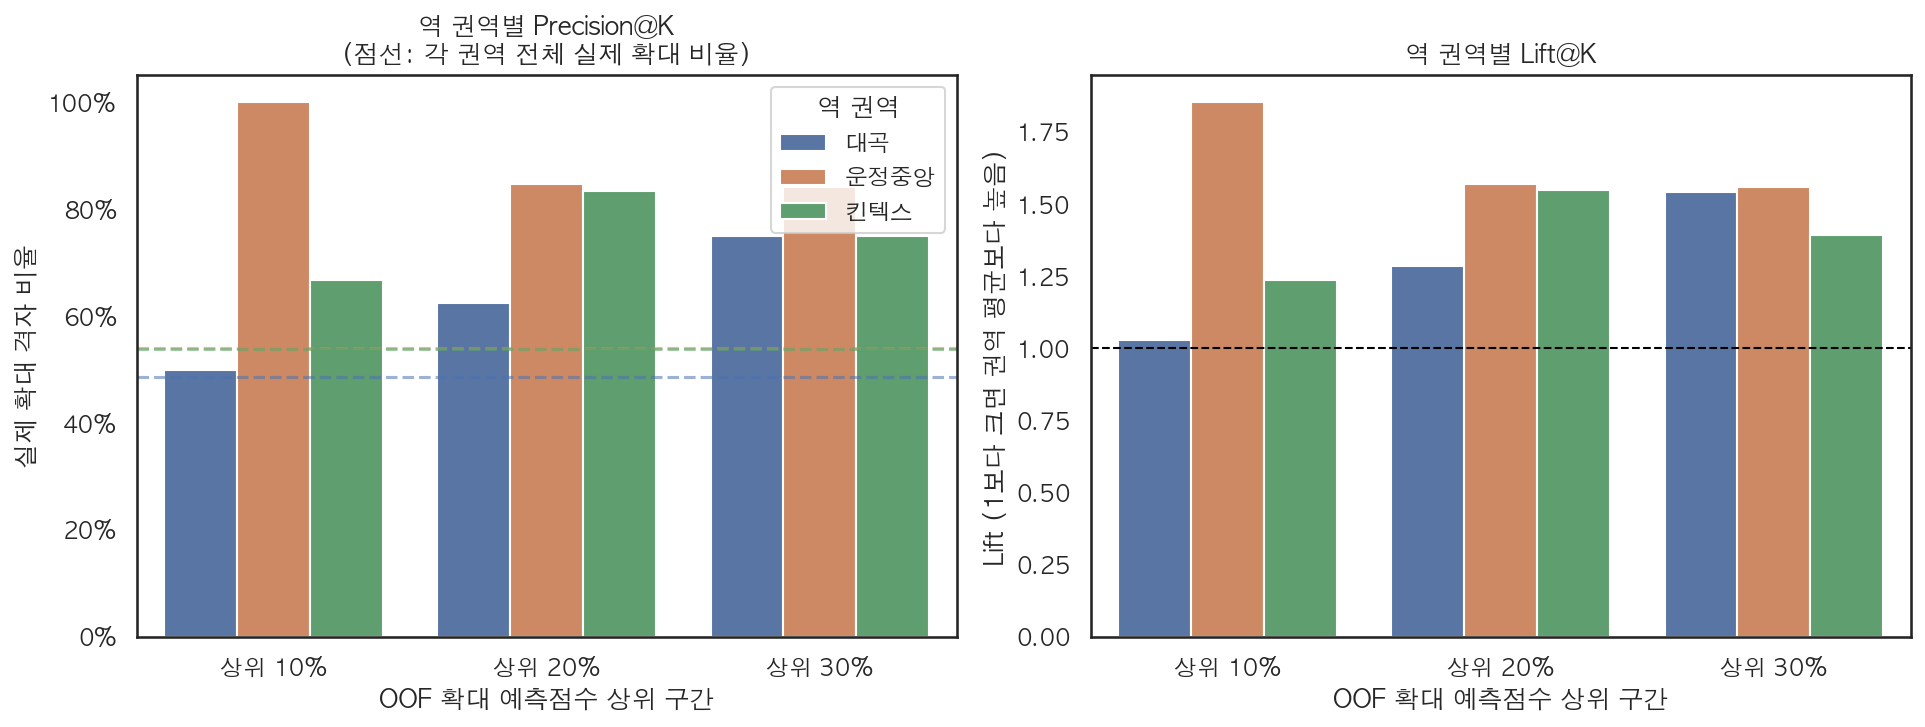

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
order = ['상위 10%', '상위 20%', '상위 30%']

sns.barplot(
    data=precision_at_k, x='상위 구간', y='Precision@K', hue='역 권역',
    order=order, hue_order=['대곡', '운정중앙', '킨텍스'], ax=axes[0]
)
for station, color in zip(['대곡', '운정중앙', '킨텍스'], sns.color_palette(n_colors=3)):
    baseline = precision_at_k.loc[
        precision_at_k['역 권역'] == station, '권역 전체 실제 확대 비율'
    ].iloc[0]
    axes[0].axhline(baseline, color=color, linestyle='--', alpha=0.55)
axes[0].set_title('역 권역별 Precision@K\n(점선: 각 권역 전체 실제 확대 비율)', weight='bold')
axes[0].set_xlabel('OOF 확대 예측점수 상위 구간')
axes[0].set_ylabel('실제 확대 격자 비율')
axes[0].set_ylim(0, 1.05)
axes[0].yaxis.set_major_formatter(lambda x, pos: f'{x:.0%}')

sns.barplot(
    data=precision_at_k, x='상위 구간', y='Lift@K', hue='역 권역',
    order=order, hue_order=['대곡', '운정중앙', '킨텍스'], ax=axes[1]
)
axes[1].axhline(1.0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('역 권역별 Lift@K', weight='bold')
axes[1].set_xlabel('OOF 확대 예측점수 상위 구간')
axes[1].set_ylabel('Lift (1보다 크면 권역 평균보다 높음)')
axes[1].legend_.remove()

plt.tight_layout()
plt.show()

### 해석 방법

세 역 모두에서 `Lift@K > 1`이면 높은 OOF 확대 예측점수를 받은 격자에서 실제 확대가 권역 평균보다 일관되게 집중된 것이다. 특정 역에서만 Lift가 높거나 K에 따라 1 아래로 내려가면 역별 일반화의 일관성이 제한적이라는 의미다. 특히 역별 표본 수가 작아 상위 10%는 소수 격자로 결정되므로, Precision@K의 작은 차이를 확정적인 성능 차이로 해석하지 않는다.